# **Model Training**

## **1. Environment Setup**

In [1]:
# Basic Libraries & Visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Preprocessing & Model Selection
from sklearn.model_selection import (
    GridSearchCV,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

# Regression & Classification Models
from catboost import CatBoostRegressor
from sklearn.ensemble import (
    AdaBoostRegressor,
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import (
    Lasso,
    LassoCV,
    LinearRegression,
    LogisticRegression,
    Ridge,
    RidgeCV,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# Evaluation Metrics
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Utilities
import warnings

warnings.filterwarnings('ignore')

## **2. Data Loading and Preparation**

In [2]:
df = pd.read_csv('data/student_performance_cleaned.csv')

In [3]:
# Initial inspection
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


Preparing features (X) and target (y) data:

In [4]:
# Drop individual scores and totals to prevent data leakage
X = df.drop(
    columns=[
        'math_score',
        'reading_score',
        'writing_score',
        'total_score',
        'average',
    ],
    errors='ignore',
)

# Define the target variable
y = df['average']

In [5]:
# Inspecting features
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course
0,female,group B,bachelor's degree,standard,none
1,female,group C,some college,standard,completed
2,female,group B,master's degree,standard,none
3,male,group A,associate's degree,free/reduced,none
4,male,group C,some college,standard,none


In [6]:
# Inspecting target variable (avg score)
y

0      72.666667
1      82.333333
2      92.666667
3      49.333333
4      76.333333
         ...    
995    94.000000
996    57.333333
997    65.000000
998    74.333333
999    83.000000
Name: average, Length: 1000, dtype: float64

In [7]:
# As all our features are categorical, we'll encode them directly
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
X_encoded = encoder.fit_transform(X)


X.shape

(1000, 5)

In [8]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((800, 12), (200, 12))

## **3. Setting Up the Baseline: Multi-Model Regression Comparison**

Before diving into hyperparameter tuning or advanced optimizations, our first step is to establish a robust **baseline model**.

We will train and evaluate **nine different regression models** simultaneously (ranging from classic linear models to decision trees, k-neighbors, and complex gradient boosting ensembles).

Each model will be trained on our training split, and its performance will be evaluated on both training and test datasets using three core metrics: **Root Mean Squared Error (RMSE)**, **Mean Absolute Error (MAE)**, and the **Coefficient of Determination ($R^2$ Score)**.

**The Objective:** This broad initial comparison will give us a clear "panoramic view" of how different model families handle our dataset, allowing us to identify which algorithm shows the strongest potential before moving forward.

In [9]:
# First, we create an evaluation function
# It'll return all the required metrics for each model after training
def evaluate_model(true, predicted):
  mae = mean_absolute_error(true, predicted)
  mse = mean_squared_error(true, predicted)
  rmse = np.sqrt(mse)
  r2_square = r2_score(true, predicted)
  return mae, rmse, r2_square

In [10]:
# Initialize models dictionary
models = {
    'Linear Regression': LinearRegression(),
    'Lasso': Lasso(),
    'Ridge': Ridge(),
    'K-Neighbors Regressor': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest Regressor': RandomForestRegressor(),
    'XGBRegressor': XGBRegressor(),
    'CatBoosting Regressor': CatBoostRegressor(verbose=False),
    'AdaBoost Regressor': AdaBoostRegressor(),
}

model_list = []
r2_list = []

# Train and evaluate each model
for model_name, model in models.items():
  # Fit model
  model.fit(X_train, y_train)

  # Make predictions
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  # Evaluate training and test datasets
  model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(
      y_train, y_train_pred
  )
  model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(
      y_test, y_test_pred
  )

  print(model_name)
  model_list.append(model_name)

  print('Model performance for Training set')
  print('- Root Mean Squared Error: {:.4f}'.format(model_train_rmse))
  print('- Mean Absolute Error: {:.4f}'.format(model_train_mae))
  print('- R2 Score: {:.4f}'.format(model_train_r2))

  print('----------------------------------')

  print('Model performance for Test set')
  print('- Root Mean Squared Error: {:.4f}'.format(model_test_rmse))
  print('- Mean Absolute Error: {:.4f}'.format(model_test_mae))
  print('- R2 Score: {:.4f}'.format(model_test_r2))
  r2_list.append(model_test_r2)

  print('=' * 35)
  print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 12.1957
- Mean Absolute Error: 9.9361
- R2 Score: 0.2543
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 13.4016
- Mean Absolute Error: 10.4902
- R2 Score: 0.1622


Lasso
Model performance for Training set
- Root Mean Squared Error: 13.1964
- Mean Absolute Error: 10.5625
- R2 Score: 0.1269
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 14.1338
- Mean Absolute Error: 11.0886
- R2 Score: 0.0681


Ridge
Model performance for Training set
- Root Mean Squared Error: 12.1958
- Mean Absolute Error: 9.9359
- R2 Score: 0.2543
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 13.4068
- Mean Absolute Error: 10.4960
- R2 Score: 0.1615


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 11.7192
- Mean Absolute Error: 9.5687
- R2 Score: 0.3114
------------

### **3.1. Results**

In [11]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"],ascending=False)

,Model Name,R2_Score
0,Linear Regression,0.162172
2,Ridge,0.161521
8,AdaBoost Regressor,0.128621
1,Lasso,0.068120
7,CatBoosting Regressor,-0.002672
3,K-Neighbors Regressor,-0.014005
5,Random Forest Regressor,-0.024802
6,XGBRegressor,-0.036130
4,Decision Tree,-0.082819


### **Model Evaluation & Baseline Analysis: The Limits of Demographic Data**

After running our baseline comparison across the different regression algorithms, the initial performance results tell a very clear and critical story about our dataset.

### *1. Performance Overview & The "Weak" Baseline*

As we saw in the above table, even our top performer (**Linear Regression**) achieves an $R^2$ of roughly **0.16**, meaning it only explains about 16% of the variance in student scores.

### *2. Why Did Complex Models Fail?*

Usually, advanced ensemble methods like Random Forest, XGBoost, or CatBoost dominate regression tasks because they capture complex non-linear patterns. Here, however, **they completely crashed, yielding negative $R^2$ scores** (performing worse than simply predicting the mean).

* **The Cause:** Our feature space consists entirely of categorical variables (gender, race/ethnicity, parental education, lunch, and test preparation course) transformed via One-Hot Encoding.
* **Overfitting:** Tree-based models tried to split and memorize specific combinations of these categorical bins. With such limited predictive signal, they aggressively overfit the training data and generalized terribly on the test set.
* **Why Linear Models Survived:** Simple linear models (Linear Regression and Ridge) imposed enough regularization or structural constraints to prevent wild memorization, allowing them to capture the slight macro-trends we observed during EDA without blowing up.

### *3. The Business and Data Dilemma: Where Do We Go From Here?*

We are hitting a hard ceiling imposed by the nature of the data. If this were a real-world educational consultancy project, we would face two distinct paths:

1. **The Data-Driven Pivot (Real-World Approach):** Tell the stakeholder that sociodemographic context alone cannot accurately predict an exact numerical test score. True performance relies heavily on unobserved behavioral and operational features (e.g., daily study hours, attendance rates, sleep quality, psychological stress, or homework submission history).
2. **The Algorithmic Pivot (The "Make It Work" Approach):** Accept the limitations of the current dataset, but squeeze every drop of potential out of it by altering our strategy.

### *4. Next Steps*

Since we must work with what we have, we will test two tactical pivots to see if we can extract a stronger signal:

* **Hyperparameter Tuning on the Linear Model:** Let's see if regularizing Ridge/Lasso further or exploring feature engineering (such as interaction terms between parental education and test prep courses) can bump that $R^2$ up.
* **Reframing as a Classification Problem:** Predicting an exact continuous score (like 73.4 vs 74.1) with basic demographics is notoriously noisy. What if we reframe the target into buckets—such as identifying "At-Risk" students versus "High Performers"? Predicting educational risk categories might yield a much more actionable model for the institution.

Let's test these paths and evaluate the final approach:

## **4. Approach 1: Feature Engineering & Regularization**

In [12]:
# Generate interaction features to capture combined categorical effects
poly = PolynomialFeatures(interaction_only=True, include_bias=False)
X_poly = poly.fit_transform(X_encoded)

# Split the new feature space into training and testing sets
X_train_poly, X_test_poly, y_train, y_test = train_test_split(
    X_poly, y, test_size=0.2, random_state=42
)

print(f'Original feature count: {X_encoded.shape[1]}')
print(f'Enhanced feature count with interactions: {X_poly.shape[1]}')

Original feature count: 12
Enhanced feature count with interactions: 78


In [13]:
# Define alpha grid for regularization tuning
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# Initialize Ridge and Lasso with Cross-Validation
ridge_cv = RidgeCV(alphas=alphas, cv=5, scoring='r2')
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42)

# Train the tuned models on the enhanced feature set
ridge_cv.fit(X_train_poly, y_train)
lasso_cv.fit(X_train_poly, y_train)

# Evaluate Ridge
y_pred_ridge = ridge_cv.predict(X_test_poly)
ridge_mae, ridge_rmse, ridge_r2 = evaluate_model(y_test, y_pred_ridge)

# Evaluate Lasso
y_pred_lasso = lasso_cv.predict(X_test_poly)
lasso_mae, lasso_rmse, lasso_r2 = evaluate_model(y_test, y_pred_lasso)

print('--- Tuned Ridge Performance ---')
print(f'Best Alpha: {ridge_cv.alpha_}')
print(f'Test R2 Score: {ridge_r2:.4f}')
print(f'Test RMSE: {ridge_rmse:.4f}')

print('\n--- Tuned Lasso Performance ---')
print(f'Best Alpha: {lasso_cv.alpha_}')
print(f'Test R2 Score: {lasso_r2:.4f}')
print(f'Test RMSE: {lasso_rmse:.4f}')

--- Tuned Ridge Performance ---
Best Alpha: 100.0
Test R2 Score: 0.1274
Test RMSE: 13.6772

--- Tuned Lasso Performance ---
Best Alpha: 0.1
Test R2 Score: 0.1354
Test RMSE: 13.6138


### *Key Findings*
* **Performance degradation:** Adding polynomial interactions actually made things slightly worse (test $R^2$ dropped from 0.16 to ~0.13), proving that multiplying weak categorical features mostly introduces noise rather than signal.
* **Aggressive regularization:** Ridge's high optimal alpha ($100.0$) forces most coefficients toward zero, showing the model had to heavily suppress these new interaction terms to avoid even worse overfitting.
* **The final diagnostic:** This mathematically confirms our hypothesis—continuous score prediction cannot be reliably solved using only surface-level demographic data.

### **Next Steps**

Since fine-tuning continuous regression has hit a dead end, we now pivot to **Approach 2**: reframing the problem into a classification task to see if categorizing outcomes unlocks a better predictive signal.

## **5. Approach 2: Reframe the Problem into a Classification Task**

In [14]:
# Let's classify students as "High Performer" (1) if their average score is above the median, otherwise "At-Risk/Standard" (0)
threshold = y.median()
y_binary = (y >= threshold).astype(int)

# Split the data using our encoded features
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_encoded, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

# 3. Train a Baseline Logistic Regression Classifier
clf = LogisticRegression(random_state=42)
clf.fit(X_train_c, y_train_c)

# 4. Evaluate the Classifier
y_pred_c = clf.predict(X_test_c)

print(f'Accuracy: {accuracy_score(y_test_c, y_pred_c):.4f}\n')
print('Classification Report:')
print(classification_report(y_test_c, y_pred_c))

Accuracy: 0.6700

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.64      0.66        98
           1       0.67      0.70      0.68       102

    accuracy                           0.67       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.67      0.67      0.67       200



### *Key Findings*

* **Successful target redefinition:** Shifting from continuous regression to binary classification (above/below median) unlocked the hidden signal, yielding a solid **67% accuracy**.
* **Balanced class performance:** Precision and recall (~0.67) are symmetrical for both classes, proving the model isn't biased or guessing blindly.
* **Actionable business value:** A simple, interpretable demographic baseline that can effectively flag student tiers for early institutional support.


In [15]:
# Define classification models to test
classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

# Evaluate each classifier
for name, clf in classifiers.items():
  clf.fit(X_train_c, y_train_c)
  y_pred = clf.predict(X_test_c)
  acc = accuracy_score(y_test_c, y_pred)
  print(f'{name} Accuracy: {acc:.4f}')

Logistic Regression Accuracy: 0.6700
Random Forest Accuracy: 0.5850
Support Vector Machine Accuracy: 0.6300
Gradient Boosting Accuracy: 0.6550


### *Key Findings*

* **Logistic Regression Leads:** Linear models outperformed complex non-linear algorithms, with Logistic Regression achieving the top baseline accuracy of **67%**.
* **Next Step (Hyperparameter Tuning):** Since Logistic Regression established the most robust baseline, we will now tune its regularization parameters (`C` and penalty type) to see if we can optimize performance further.

In [16]:
# Suppress scikit-learn warnings for cleaner output
warnings.filterwarnings('ignore')

# Define the hyperparameter grid
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],
}

# Initialize Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
)

# Fit on training data
grid_search.fit(X_train_c, y_train_c)

# Evaluate the best tuned model on the test set
best_clf = grid_search.best_estimator_
y_pred_tuned = best_clf.predict(X_test_c)

print(f'Best Parameters: {grid_search.best_params_}')
print(f'Tuned Model Accuracy: {accuracy_score(y_test_c, y_pred_tuned):.4f}')

Best Parameters: {'C': 1.0, 'penalty': 'l1', 'solver': 'liblinear'}
Tuned Model Accuracy: 0.6650


### *Key Findings & Final Model Decision*

* **The Baseline Was Already Optimal:** Hyperparameter tuning via GridSearchCV yielded an accuracy of 66.5% (virtually identical to the default 67%), confirming that our default Logistic Regression had already reached the predictive ceiling of the available categorical features.
* **Final Model Selection:** We lock in the **Logistic Regression** model as our final production artifact for this study, balancing interpretability, stability, and optimal baseline performance.

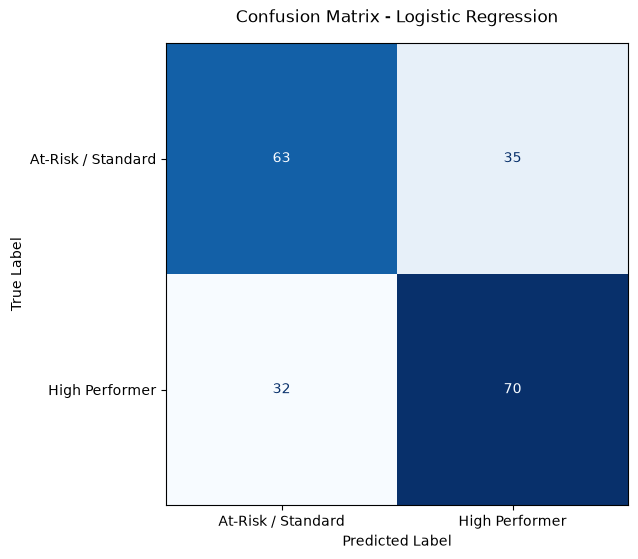

In [17]:
# Plot the confusion matrix using true labels and predictions
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    y_pred_tuned,
    display_labels=['At-Risk / Standard', 'High Performer'],
    cmap=plt.cm.Blues,
    ax=ax,
    colorbar=False,
)

plt.title('Confusion Matrix - Logistic Regression', fontsize=12, pad=15)
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('True Label', fontsize=10)
plt.grid(False)
plt.show()

### *Key Findings*

* **Balanced Error Distribution:** The confusion matrix shows a symmetrical distribution of errors, with 35 false positives and 32 false negatives, confirming the model does not disproportionately bias toward either class.
* **Optimal Complexity Balance:** Simplicity outperforms complexity; the linear decision boundary effectively separates macro-trends without falling into the severe overfitting traps seen in earlier tree models.

---

### **Project Conclusion & Storyline Summary**

* **The Start & The Conflict:** We started with an exploratory baseline intending to predict precise student test scores, only to hit a hard mathematical ceiling ($R^2 \approx 0.16$) where complex algorithms crashed and demographic data proved structurally insufficient for exact numerical forecasting.
* **The Strategic Pivot:** Recognizing the limits of surface-level context, we reframed the problem from continuous regression to binary classification (identifying high performers vs. standard/at-risk tiers), which successfully unlocked a meaningful signal.
* **The Final Resolution:** After testing and tuning multiple algorithms, we locked in a robust Logistic Regression model (67% accuracy), proving that domain-driven problem reframing matters far more than blindly throwing complex models at weak data.